In [ ]:
import marimo as mo
import matplotlib.pyplot as plt
import polars as pl
import seaborn as sns
from skimpy import skim
import sweetviz as sv
from data_profiling import ProfileReport

from pathlib import Path

from src.data import load_data

In [ ]:

base_path = Path("/Users/platon/Documents/kaggle-house")

curr_path = Path(__file__).parent
html_path = curr_path/'htmls'
html_path.mkdir(exist_ok=True)

In [ ]:
train_dataset = load_data(base_path / "data/train.csv")
test_dataset = load_data(base_path / "data/test.csv")

In [ ]:
train_dataset['SalePrice']

SalePrice
i64
208500
181500
223500
140000
250000
…
175000
210000
266500


еще короч важно переводить sales prices в log1p, типо, например, потому что метрика в катбусте только rmse, а нам надо уменьшать rmsle

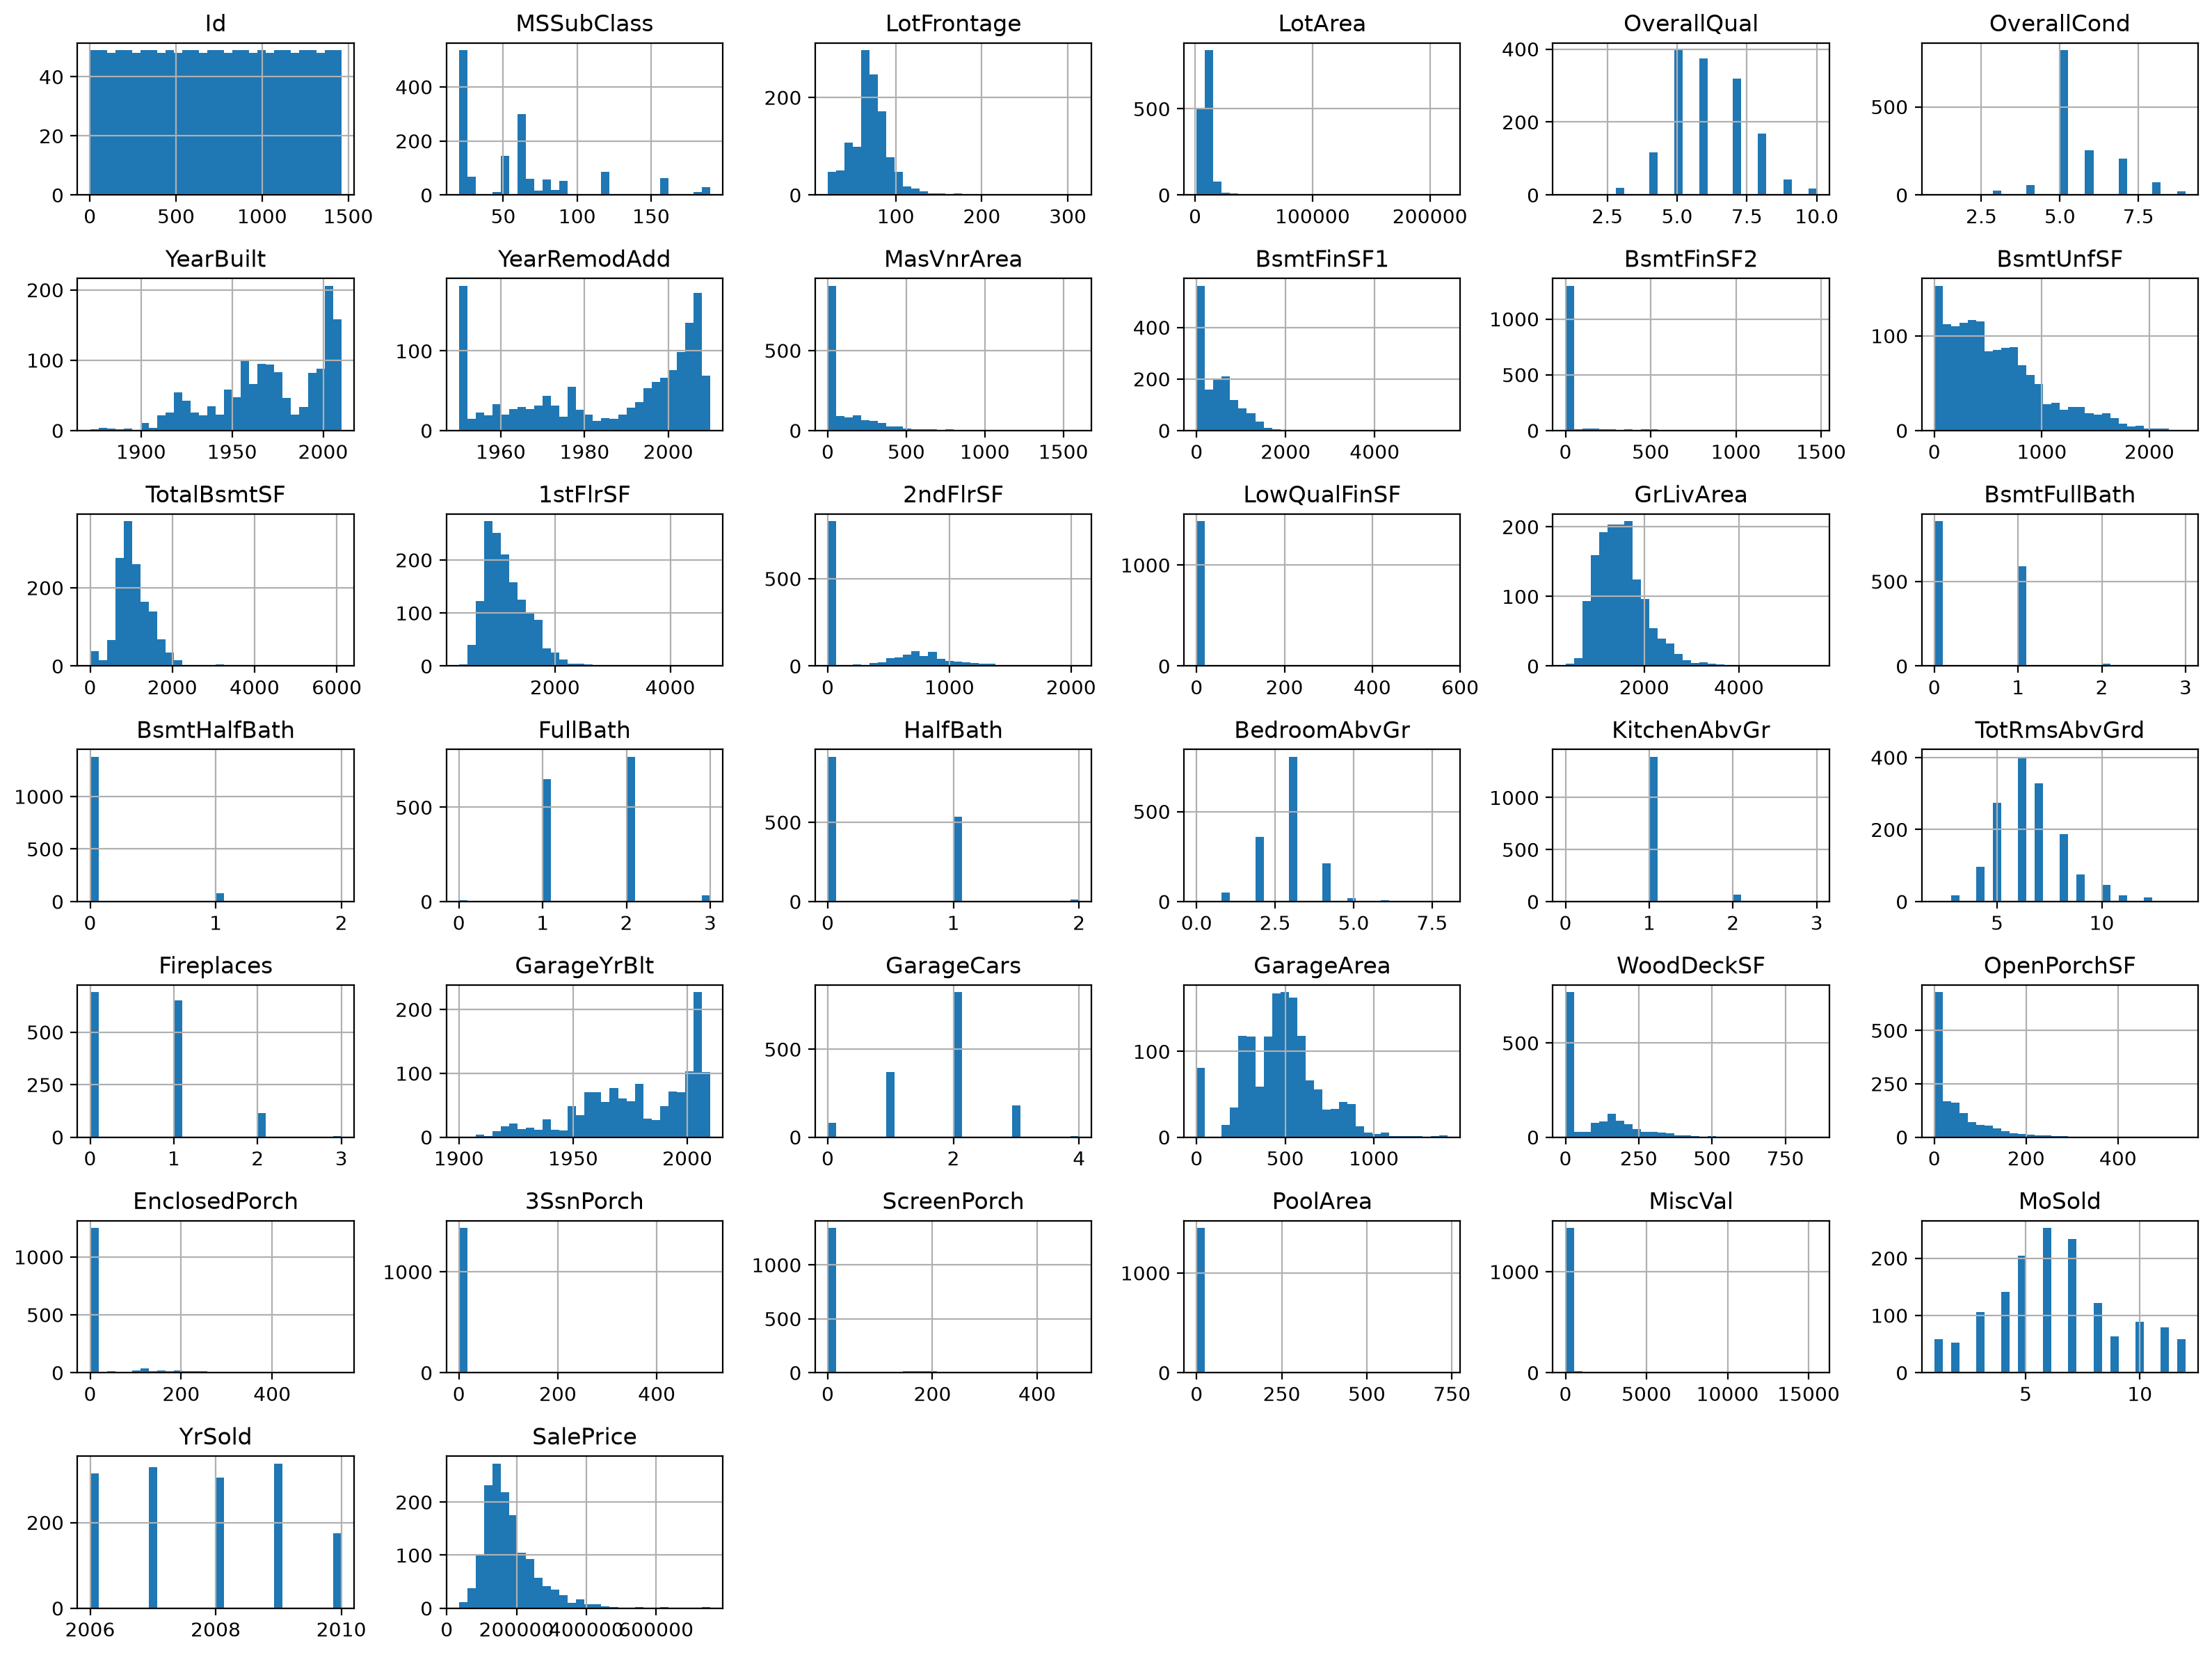

In [ ]:
train_dataset.to_pandas().hist(figsize=(16, 12), bins=30)
plt.tight_layout()
plt.show()

In [ ]:
skimpy_summary = skim(train_dataset)

╭─────────────────────────────── skimpy summary ───────────────────────────────╮
│          Data Summary                Data Types                              │
│ ┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓ ┏━━━━━━━━━━━━━┳━━━━━━━┓                       │
│ ┃ Dataframe         ┃ Values ┃ ┃ Column Type ┃ Count ┃                       │
│ ┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩ ┡━━━━━━━━━━━━━╇━━━━━━━┩                       │
│ │ Number of rows    │ 1460   │ │ string      │ 43    │                       │
│ │ Number of columns │ 81     │ │ int64       │ 35    │                       │
│ └───────────────────┴────────┘ │ float64     │ 3     │                       │
│                                └─────────────┴───────┘                       │
│                                   number                                     │
│ ┏━━━━━━┳━━━━━┳━━━━━━┳━━━━━━┳━━━━━━┳━━━━━━┳━━━━━━┳━━━━━┳━━━━━━┳━━━━━┳━━━━━━┓  │
│ ┃ colu ┃     ┃      ┃      ┃      ┃      ┃      ┃     ┃      ┃ p10 ┃      ┃  │
│ ┃ mn   ┃ NA  ┃ NA % ┃ mean

skimpy — малочитабельно для столь обширного кол-ва фичей. но можно быстро пробежаться и посмотреьт еще и на категориальные

In [ ]:
train_pd = train_dataset.to_pandas()
test_pd = test_dataset.to_pandas()

In [ ]:
report_dp = ProfileReport(train_pd, title="House Prices EDA")
report_dp.to_file(html_path/ "eda_profile.html")


Summarize dataset:  20%|█▉        | 17/86 [00:00<00:00, 158.80it/s, Describe variable: Exterior2nd]

Summarize dataset:  43%|████▎     | 37/86 [00:00<00:00, 170.50it/s, Describe variable: GrLivArea]

Summarize dataset:  77%|███████▋  | 66/86 [00:00<00:00, 129.82it/s, Describe variable: MiscVal]

100%|██████████| 81/81 [00:00<00:00, 275.32it/s]

Summarize dataset: 100%|██████████| 991/991 [00:49<00:00, 19.92it/s, Completed]

Generate report structure: 100%|██████████| 1/1 [00:06<00:00,  6.87s/it]

Render HTML: 100%|██████████| 1/1 [00:02<00:00,  2.24s/it]

Export report to file: 100%|██████████| 1/1 [00:00<00:00, 16.46it/s]


In [ ]:
report_sv = sv.analyze(train_pd, target_feat="SalePrice")


                                             |          | [  0%]   00:00 -> (? left)
[Summarizing dataframe]                      |          | [  0%]   00:00 -> (? left)
Feature: SalePrice (TARGET)                  |          | [  1%]   00:00 -> (00:00 left)findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.

Feature: SalePrice (TARGET)   

In [ ]:
report_sv.show_html(html_path/ 'eda_profile_sv.html')

Report /Users/platon/Documents/kaggle-house/notebooks/htmls/eda_profile_sv.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.


In [ ]:
report_compare = sv.compare(
    [train_pd.drop(columns=["SalePrice", "Id"]), "Train"],
    [test_pd.drop(columns=["Id"]), "Test"],
)
report_compare.show_html(html_path/ "eda_train_test.html")


                                             |          | [  0%]   00:00 -> (? left)
[Summarizing dataframe]                      |          | [  0%]   00:00 -> (? left)
Feature: MSSubClass                          |▏         | [  1%]   00:00 -> (00:02 left)findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.

Feature: MSSubClass           

Report /Users/platon/Documents/kaggle-house/notebooks/htmls/eda_train_test.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.


- фича Alley — там чет 94% NA
- фича Street — там чет 99% одного значения
- фича Utilities — там чет 99% одного значения
- фича LandSlop - 95% одного значения и еще два других значения по 4% и 1%
- фича Condition2 — 99% одного значения и еще 7 других значений по 1%
- фича RoofMatl — 98% одного значения и еще 7 других значений по 1%, но есть какая-то корреляция с SalePrice = 0.18
- фича BsmtFinSF2 — чет просто странная, там 88% нулей, а остальные значения почти все разные, диапазон от 0 до 1474
- фича BsmtHalfBath — там 94% нулей, а остальные странные тоже, думаю точно удалять стоит
- фича FireplaceQu — там 47% NA, нужно чем-то заполнять, но как? может просто 0, а потом сделать категориальную фичу есть камин или нет
- фича EnclosedPorch, 3SsnPorch, ScreenPorch — там >85% одно значение, а остальные раскиданы сильно, надо подумать, мб просто добавить фичу, есть веранда или нет, а потом сделать категориальную фичу, что за веранда
- фича PoolArea — там 99% нулей, просто в категориальную фичу, есть бассейн или нет
- фича PoolQC - там 99% NA нах
- фича Fence — там 81% NA, нужно чем-то заполнять, но как? может просто "IDK", а потом сделать категориальную фичу есть забор или нет
- фича MiscFeature - там 96% NA, как будто просто удалить
- фича MiscVal — там 96.4% нулей, как будто делит
- фича YrSold — чуть бесполезная фича вроде, там везде одна цена по сути 181к +- 4к, можно делит?

findfont: Failed to find font weight normal for Roboto, now using 500.


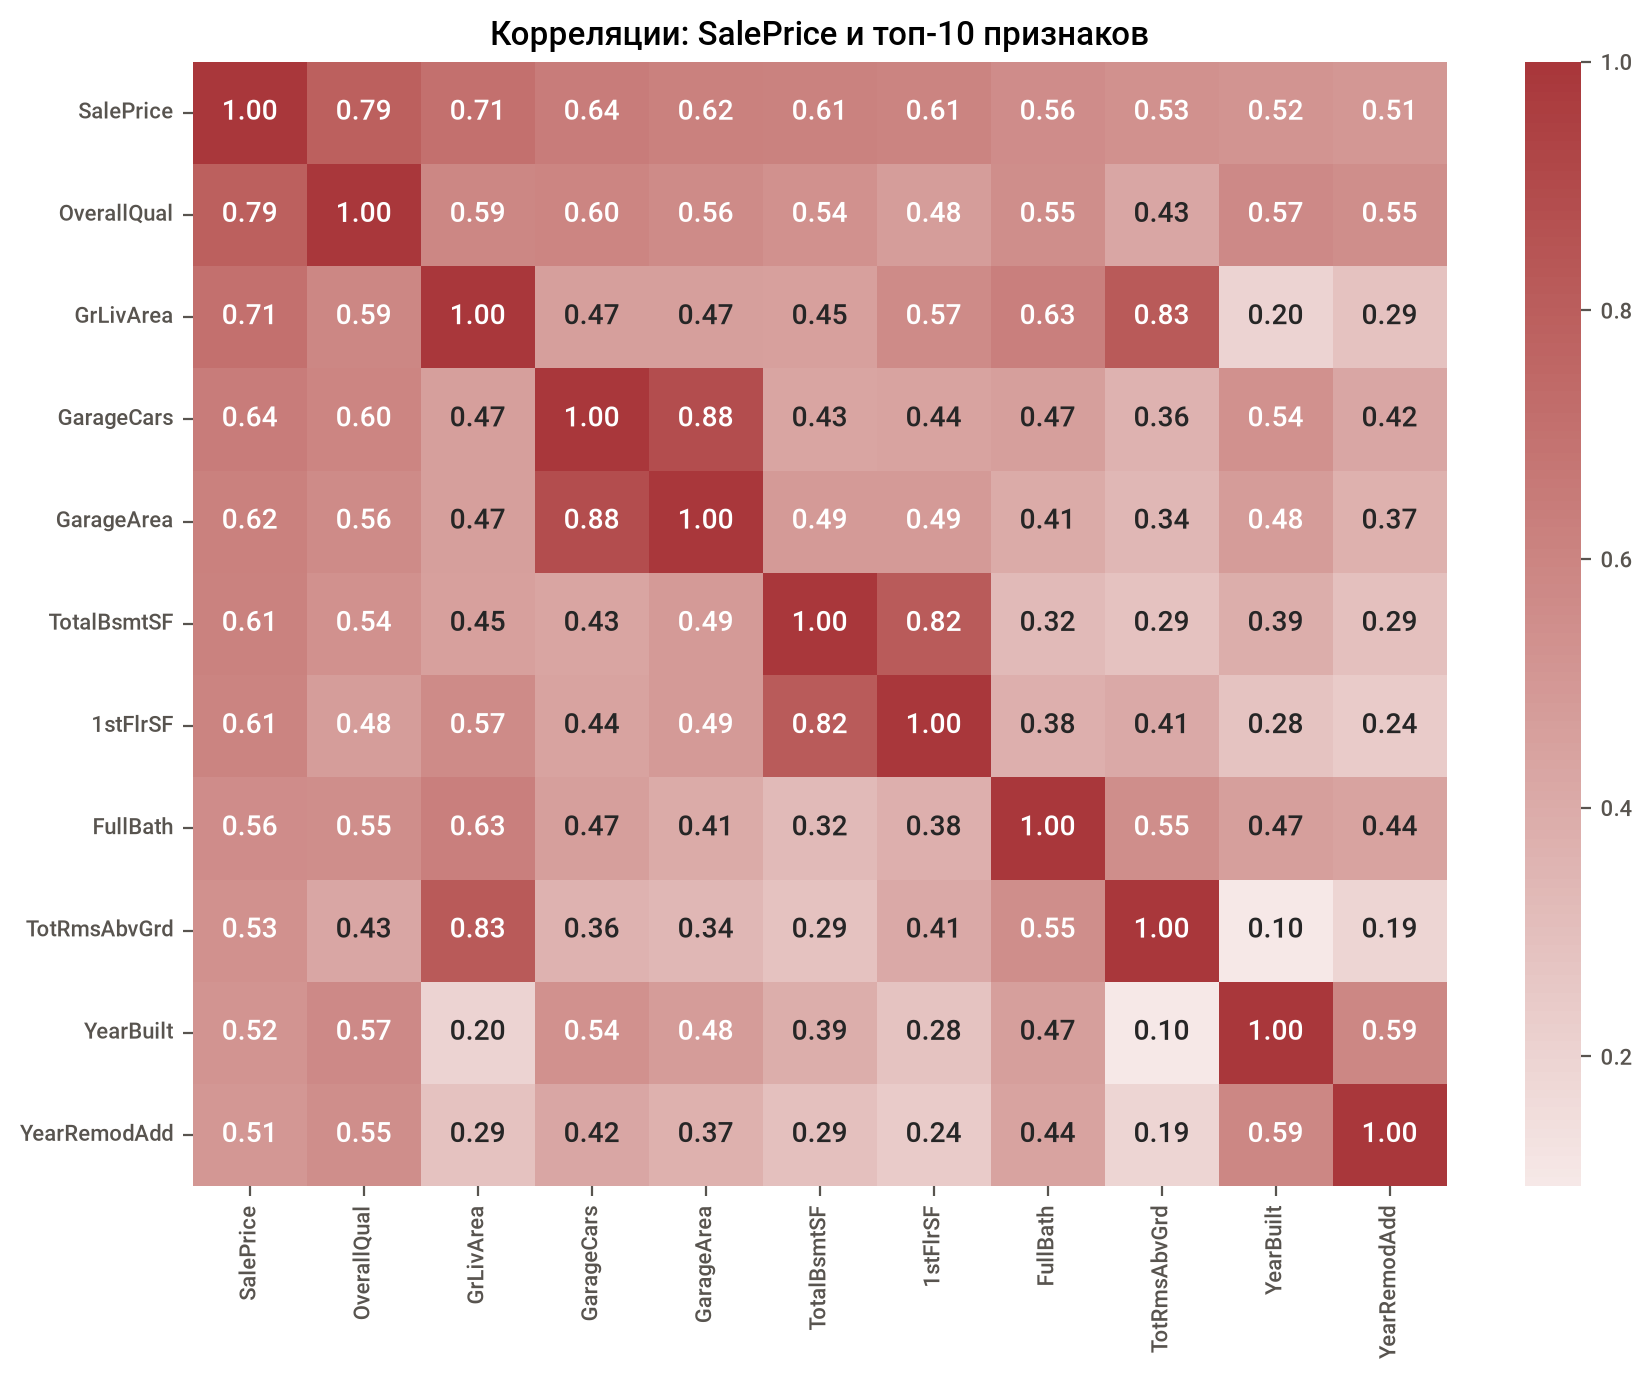

In [ ]:
_top = train_pd.select_dtypes("number").corr()["SalePrice"].abs().sort_values(ascending=False).index[:11]
_fig, _ax = plt.subplots(figsize=(9, 7))
sns.heatmap(train_pd[_top].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, ax=_ax)
_ax.set_title("Корреляции: SalePrice и топ-10 признаков")
_fig.tight_layout()
_fig

еще короче нашел, что GrLivArea есть выбросы в данных, которые чуть мешают модели, там короче есть нетипичные сделки. короче можно наверно рубтть от 4000 потому что там есть какие-то : 5642	160000, 4676	184750, 3395	200000, в тоже время 4476	745000, 4316	755000, 3608	475000, короче страненько, эт ес че было "GrLivArea", "SalePrice"

In [ ]:
train_dataset.filter(pl.col("GrLivArea") >= 3000).select("GrLivArea", "SalePrice").sort('GrLivArea')

GrLivArea,SalePrice
i64,i64
3082,197000
3086,200500
3112,235000
3140,485000
3194,359100
…,…
3627,625000
4316,755000
4476,745000


In [ ]:
test_dataset.filter(pl.col("GrLivArea") > 4000)

Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,…,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
i64,i64,str,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,i64,i64,i64,i64,str,str,str,str,str,i64,str,str,str,str,str,str,str,i64,str,i64,…,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,str,i64,str,i64,str,str,i64,str,i64,i64,str,str,str,i64,i64,i64,i64,i64,i64,str,str,str,i64,i64,i64,str,str
2550,20,"""RL""",128,39290,"""Pave""","""NA""","""IR1""","""Bnk""","""AllPub""","""Inside""","""Gtl""","""Edwards""","""Norm""","""Norm""","""1Fam""","""1Story""",10,5,2008,2009,"""Hip""","""CompShg""","""CemntBd""","""CmentBd""","""Stone""",1224,"""Ex""","""TA""","""PConc""","""Ex""","""TA""","""Gd""","""GLQ""",4010,"""Unf""",0,…,5095,0,0,5095,1,1,2,1,2,1,"""Ex""",15,"""Typ""",2,"""Gd""","""Attchd""",2008,"""Fin""",3,1154,"""TA""","""TA""","""Y""",546,484,0,0,0,0,"""NA""","""NA""","""NA""",17000,10,2007,"""New""","""Partial"""
